# 02 — Data Cleaning

## Objective

The objective of this notebook is to identify and handle potential data quality issues in the Car Price Prediction dataset.

The cleaning process focuses on detecting duplicate records, missing values, statistical outliers, and inconsistent categorical values.

## Steps

1. Import the required libraries.
2. Load the original dataset.
3. Detect and handle duplicate records.
4. Detect and investigate missing values.
5. Detect statistical outliers using the IQR method.
6. Investigate potential outliers before deciding whether to remove them.
7. Check categorical values and their distributions.
8. Perform final data validation.
9. Export the cleaned dataset.

## Expected Outcome

Produce a clean and validated dataset that can be used for exploratory data analysis and model development.

In [1]:
### 1. Import Libraries
import pandas as pd

In [3]:
### 2. Load the Original Dataset
df = pd.read_csv('../data/raw/Car_Price_Prediction.csv')

In [4]:
### 3. Detect and Handle Duplicates
df.duplicated().sum()

np.int64(0)

In [5]:
### 4. Detect and Analyze Missing Values
df.isnull().sum().sum()

np.int64(0)

In [6]:
### 5. Detect Statistical Outliers Using IQR
for col in df.select_dtypes('number').columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nFeature: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

out = df.loc[outliers.index]
out


Feature: Year
Lower Bound: 1988.5
Upper Bound: 2032.5
Number of Outliers: 0

Feature: Engine Size
Lower Bound: -0.8000000000000003
Upper Bound: 6.4
Number of Outliers: 0

Feature: Mileage
Lower Bound: -111544.75
Upper Bound: 305291.25
Number of Outliers: 0

Feature: Price
Lower Bound: 10760.142462737595
Upper Bound: 39634.10488078541
Number of Outliers: 3


,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
133,BMW,Model A,2019,3.5,10315,Electric,Manual,41780.504635
295,Ford,Model C,2020,4.5,50886,Petrol,Manual,40538.382064
981,Audi,Model B,2000,1.1,181142,Diesel,Automatic,6704.953524


In [7]:
### 6. Investigate Potential Outliers
df[
    (df["Make"] == "Ford") &
    (df["Model"] == "Model C") &
    (df["Year"] == 2020)
].sort_values("Price")

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
979,Ford,Model C,2020,1.0,27898,Petrol,Manual,27478.657518
295,Ford,Model C,2020,4.5,50886,Petrol,Manual,40538.382064


In [8]:
df[
    (df["Make"] == "Audi") &
    (df["Model"] == "Model B") &
    (df["Year"] == 2000)
].sort_values("Price")

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
981,Audi,Model B,2000,1.1,181142,Diesel,Automatic,6704.953524
6,Audi,Model B,2000,1.3,179340,Diesel,Manual,12268.206025


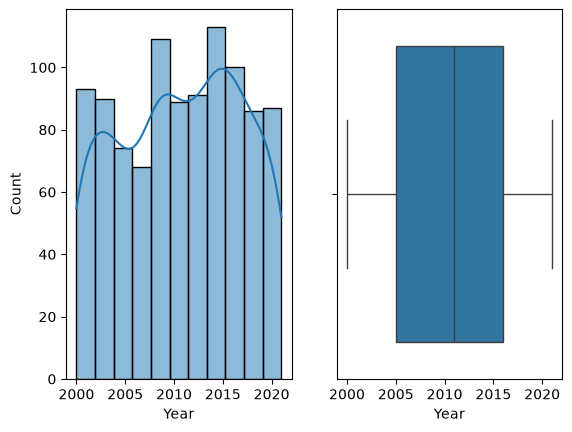

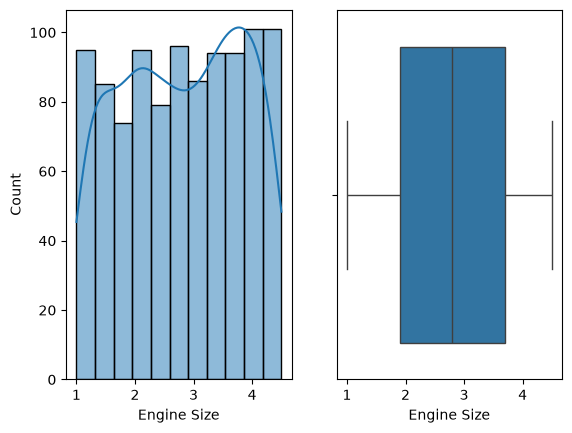

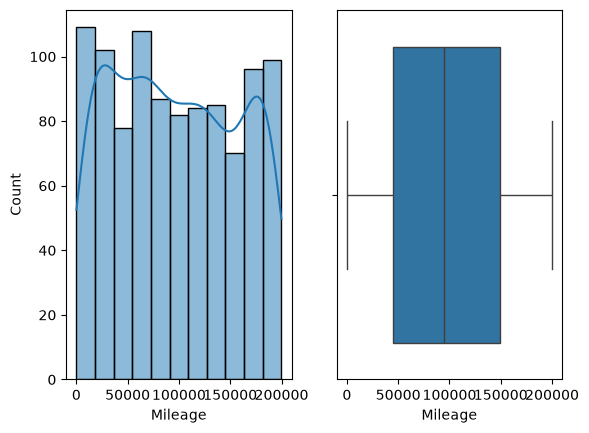

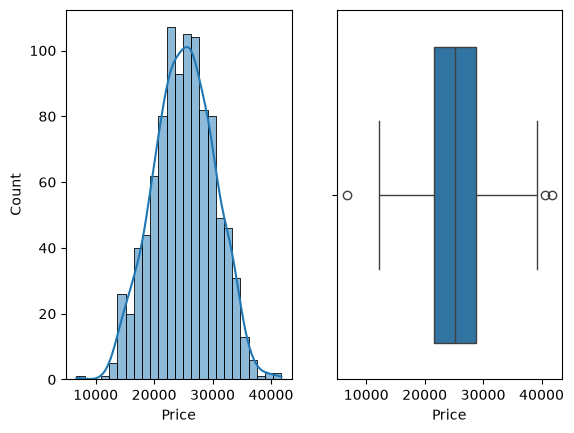

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in df.select_dtypes('number').columns:
    fig, ax = plt.subplots(1,2)
    sns.histplot(x=df[col],kde=True,ax=ax[0])
    sns.boxplot(x=df[col],ax=ax[1])
    plt.show()

In [10]:
### 7. Check Categorical Values
for col in df.select_dtypes('str').columns:
    print(df[col].value_counts())
    print()


Make
Ford      225
Audi      212
Honda     198
Toyota    187
BMW       178
Name: count, dtype: int64

Model
Model B    212
Model C    205
Model A    202
Model D    197
Model E    184
Name: count, dtype: int64

Fuel Type
Diesel      344
Petrol      331
Electric    325
Name: count, dtype: int64

Transmission
Manual       511
Automatic    489
Name: count, dtype: int64



In [11]:
### 8. Perform Final Data Validation
df_clean = df.drop(df[(df['Price'] <= 10760.14) | (df['Price'] >= 39634.10)].index, axis=0).reset_index(drop=True)
df_clean.shape

(997, 8)

In [12]:
df_clean.describe()

,Year,Engine Size,Mileage,Price
count,997.000000,997.000000,997.000000,997.000000
mean,2010.681043,2.797593,97241.869609,25122.960572
std,6.276476,1.022603,59395.443445,5105.899385
min,2000.000000,1.000000,56.000000,12268.206025
25%,2005.000000,1.900000,44859.000000,21601.804620
50%,2011.000000,2.800000,94605.000000,25188.335182
75%,2016.000000,3.700000,148933.000000,28794.448971
max,2021.000000,4.500000,199867.000000,39203.514073


In [47]:
df_clean.describe(include='str')

,Make,Model,Fuel Type,Transmission
count,997,997,997,997
unique,5,5,3,2
top,Ford,Model B,Diesel,Manual
freq,224,211,343,509


In [13]:
### 9. Export the Cleaned Dataset
df_clean.to_csv("../data/processed/cleaned_data.csv",index=False)